In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
RESULTADOS = Path('/content/drive/MyDrive/retinopatia/resultados')
FIGURAS = RESULTADOS / 'figuras_articulo'
FIGURAS.mkdir(exist_ok=True)

MODELOS = {'efficientnet_b0': 'EfficientNet-B0', 'resnet50': 'ResNet-50'}
COLOR_FASE = {'train': '#1f4e79', 'val': '#c55a11'}
COLOR_MODELO = {'efficientnet_b0': '#1f4e79', 'resnet50': '#2e8b57'}
EPOCAS_CABEZA = 2

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'legend.fontsize': 8, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'savefig.bbox': 'tight',
})


def leer(nombre):
    return pd.read_csv(RESULTADOS / f'historial_{nombre}.csv')


def marcar_fase_cabeza(ax):
    ax.axvspan(0.5, EPOCAS_CABEZA + 0.5, color='0.9', zorder=0, lw=0)


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f'{nombre}.pdf')
    fig.savefig(FIGURAS / f'{nombre}.png', dpi=200)
    plt.show()

Mounted at /content/drive


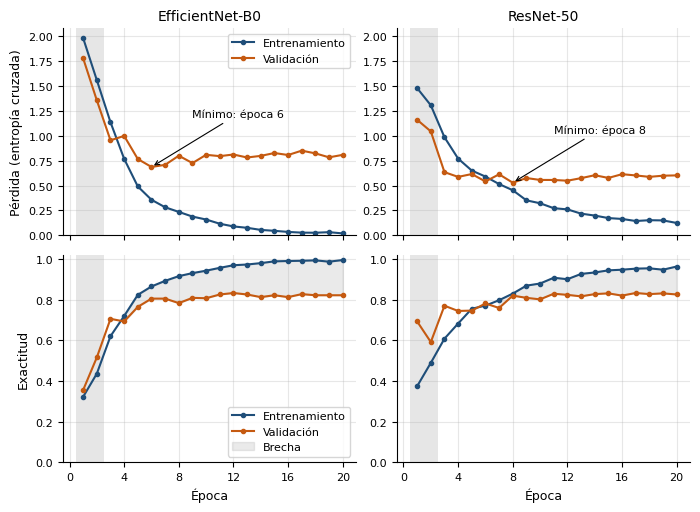

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5.2), sharex=True)
historiales = {arq: leer(f'{arq}_final') for arq in MODELOS}
techo_perdida = max(h[['perdida_train', 'perdida_val']].max().max() for h in historiales.values())

for j, (arq, nombre) in enumerate(MODELOS.items()):
    h = historiales[arq]

    ax = axes[0, j]
    marcar_fase_cabeza(ax)
    ax.plot(h['epoca'], h['perdida_train'], color=COLOR_FASE['train'], marker='o', ms=3, label='Entrenamiento')
    ax.plot(h['epoca'], h['perdida_val'], color=COLOR_FASE['val'], marker='o', ms=3, label='Validación')
    fila_min = h.loc[h['perdida_val'].idxmin()]
    ax.annotate(f'Mínimo: época {int(fila_min["epoca"])}',
                xy=(fila_min['epoca'], fila_min['perdida_val']),
                xytext=(fila_min['epoca'] + 3, fila_min['perdida_val'] + 0.5),
                arrowprops={'arrowstyle': '->', 'lw': 0.8}, fontsize=8)
    ax.set_ylim(0, techo_perdida * 1.05)
    ax.set_title(nombre)

    ax = axes[1, j]
    marcar_fase_cabeza(ax)
    ax.plot(h['epoca'], h['exactitud_train'], color=COLOR_FASE['train'], marker='o', ms=3, label='Entrenamiento')
    ax.plot(h['epoca'], h['exactitud_val'], color=COLOR_FASE['val'], marker='o', ms=3, label='Validación')
    ax.fill_between(h['epoca'], h['exactitud_val'], h['exactitud_train'],
                    where=h['exactitud_train'] >= h['exactitud_val'],
                    color='0.6', alpha=0.2, label='Brecha')
    ax.set_ylim(0, 1.02)
    ax.set_xlabel('Época')

axes[0, 0].set_ylabel('Pérdida (entropía cruzada)')
axes[1, 0].set_ylabel('Exactitud')
axes[0, 0].legend(loc='upper right')
axes[1, 0].legend(loc='lower right')
axes[1, 0].set_xticks(range(0, 21, 4))
fig.tight_layout()
guardar(fig, 'fig_curvas_modelos_finales')

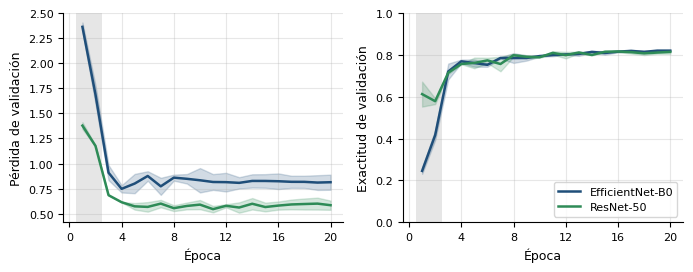

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True)
columnas = [('perdida_val', 'Pérdida de validación'), ('exactitud_val', 'Exactitud de validación')]

for arq, nombre in MODELOS.items():
    folds = [leer(f'{arq}_fold{k}') for k in [0, 1]]
    epocas = folds[0]['epoca']
    for ax, (col, etiqueta) in zip(axes, columnas):
        valores = np.vstack([f[col].to_numpy() for f in folds])
        ax.plot(epocas, valores.mean(axis=0), color=COLOR_MODELO[arq], lw=1.8, label=nombre)
        ax.fill_between(epocas, valores.min(axis=0), valores.max(axis=0),
                        color=COLOR_MODELO[arq], alpha=0.2)
        ax.set_ylabel(etiqueta)

for ax in axes:
    marcar_fase_cabeza(ax)
    ax.set_xlabel('Época')
    ax.set_xticks(range(0, 21, 4))
axes[1].set_ylim(0, 1)
axes[1].legend(loc='lower right')
fig.tight_layout()
guardar(fig, 'fig_validacion_cruzada')

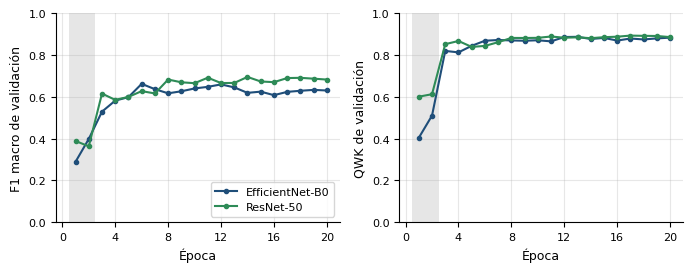

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True)
columnas = [('f1_macro_val', 'F1 macro de validación'), ('qwk_val', 'QWK de validación')]

for arq, nombre in MODELOS.items():
    h = historiales[arq]
    for ax, (col, etiqueta) in zip(axes, columnas):
        ax.plot(h['epoca'], h[col], color=COLOR_MODELO[arq], marker='o', ms=3, label=nombre)
        ax.set_ylabel(etiqueta)

for ax in axes:
    marcar_fase_cabeza(ax)
    ax.set_xlabel('Época')
    ax.set_xticks(range(0, 21, 4))
    ax.set_ylim(0, 1)
axes[0].legend(loc='lower right')
fig.tight_layout()
guardar(fig, 'fig_f1_qwk_finales')

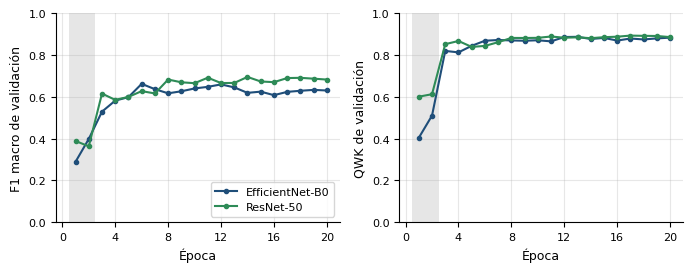

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True)
columnas = [('f1_macro_val', 'F1 macro de validación'), ('qwk_val', 'QWK de validación')]

for arq, nombre in MODELOS.items():
    h = historiales[arq]
    for ax, (col, etiqueta) in zip(axes, columnas):
        ax.plot(h['epoca'], h[col], color=COLOR_MODELO[arq], marker='o', ms=3, label=nombre)
        ax.set_ylabel(etiqueta)

for ax in axes:
    marcar_fase_cabeza(ax)
    ax.set_xlabel('Época')
    ax.set_xticks(range(0, 21, 4))
    ax.set_ylim(0, 1)
axes[0].legend(loc='lower right')
fig.tight_layout()
guardar(fig, 'fig_f1_qwk_finales')

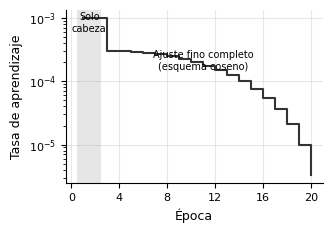

In [6]:
h = historiales['efficientnet_b0']
fig, ax = plt.subplots(figsize=(3.4, 2.4))
marcar_fase_cabeza(ax)
ax.step(h['epoca'], h['lr'], where='post', color='0.2')
ax.set_yscale('log')
ax.set_xlabel('Época')
ax.set_ylabel('Tasa de aprendizaje')
ax.set_xticks(range(0, 21, 4))
ax.text(1.5, h['lr'].max() * 0.6, 'Solo\ncabeza', ha='center', fontsize=7)
ax.text(11, h['lr'].max() * 0.15, 'Ajuste fino completo\n(esquema coseno)', ha='center', fontsize=7)
fig.tight_layout()
guardar(fig, 'fig_tasa_aprendizaje')